# Nested-CV Error Review

Combine outer-test predictions from all completed folds and inspect false positives and false negatives at the fixed 0.5 threshold. Each clip occurs in exactly one outer test fold.

In [5]:
from pathlib import Path
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
from IPython.display import Audio, display

def find_project_root(start=None):
    path = Path(start or Path.cwd()).resolve()
    for candidate in [path, *path.parents]:
        config = candidate / 'project_config.py'
        if (candidate / 'workspace').exists() and config.exists():
            return candidate
    raise FileNotFoundError('Run this notebook from the project or flattened server working directory.')

PROJECT_ROOT = find_project_root()
CONFIG_DIR = PROJECT_ROOT
if str(CONFIG_DIR) not in sys.path:
    sys.path.insert(0, str(CONFIG_DIR))

from project_config import BINARY_LABELS_PATH, CLIPS_DIR, WORKSPACE_DIR

MODEL_ROOT = Path(os.environ.get('STORM_PETREL_MODEL_ROOT', WORKSPACE_DIR / 'models' / 'nested_cv_balanced')).expanduser().resolve()

THRESHOLD = 0.5
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', 160)
print(f'Model root: {MODEL_ROOT}')

Model root: /home/zenith/Projects/strom_petrels/workspace/models/nested_cv_balanced


## Combine Outer-test Predictions

In [6]:
prediction_rows = []
for outer_dir in sorted(MODEL_ROOT.glob('outer_*')):
    path = outer_dir / 'predictions.csv'
    if path.is_file():
        part = pd.read_csv(path)
        part['outer_fold'] = outer_dir.name.removeprefix('outer_')
        prediction_rows.append(part)

if not prediction_rows:
    raise FileNotFoundError(f'No predictions.csv files under {MODEL_ROOT}')

pred = pd.concat(prediction_rows, ignore_index=True)
pred['score'] = pd.to_numeric(pred['score'])
pred['true_label'] = pd.to_numeric(pred['true_label'])
pred['file_name'] = pred['file'].map(lambda value: Path(str(value)).name)
pred['predicted_label'] = (pred['score'] >= THRESHOLD).astype(int)

labels = pd.read_csv(BINARY_LABELS_PATH)
labels['file_name'] = labels['clip_id'].astype(str) + '.wav'
metadata_columns = ['file_name', 'clip_id', 'negative_type', 'species', 'source_file', 'clip_path']
pred = pred.merge(labels[metadata_columns], on='file_name', how='left')

false_positives = pred[(pred.true_label == 0) & (pred.predicted_label == 1)].sort_values('score', ascending=False)
false_negatives = pred[(pred.true_label == 1) & (pred.predicted_label == 0)].sort_values('score')

print(f'Predictions: {len(pred):,} from {pred.outer_fold.nunique()} folds')
print(f'False positives at {THRESHOLD}: {len(false_positives)}')
print(f'False negatives at {THRESHOLD}: {len(false_negatives)}')
display(false_positives.head(30))
display(false_negatives.head(30))

Predictions: 2,000 from 5 folds
False positives at 0.5: 5
False negatives at 0.5: 4


,file,class_folder,true_label,score,outer_fold,file_name,predicted_label,clip_id,negative_type,species,source_file,clip_path
39,/mnt/data2/skokholm/alyzw89/workspace/nested_cv_datasets/outer_01/test/not_storm_petrel/environment_noise_01636_042_210803_211120_0007494000.wav,not_storm_petrel,0,1.780659,01,environment_noise_01636_042_210803_211120_0007494000.wav,1,environment_noise_01636_042_210803_211120_0007494000,environment_noise,Engine_Engine,042_210803_211120.flac,/mnt/data2/skokholm/alyzw89/workspace/clips/not_storm_petrel/environment_noise_01636_042_210803_211120_0007494000.wav
1685,/mnt/data2/skokholm/alyzw89/workspace/nested_cv_datasets/outer_05/test/not_storm_petrel/environment_noise_01857_042_210628_225556_0019977000.wav,not_storm_petrel,0,1.364355,05,environment_noise_01857_042_210628_225556_0019977000.wav,1,environment_noise_01857_042_210628_225556_0019977000,environment_noise,Dog_Dog,042_210628_225556.flac,/mnt/data2/skokholm/alyzw89/workspace/clips/not_storm_petrel/environment_noise_01857_042_210628_225556_0019977000.wav
1320,/mnt/data2/skokholm/alyzw89/workspace/nested_cv_datasets/outer_04/test/not_storm_petrel/other_bird_01272_067_210716_213947_0015075000.wav,not_storm_petrel,0,1.302391,04,other_bird_01272_067_210716_213947_0015075000.wav,1,other_bird_01272_067_210716_213947_0015075000,other_bird,Puffinus puffinus_Manx Shearwater,067_210716_213947.flac,/mnt/data2/skokholm/alyzw89/workspace/clips/not_storm_petrel/other_bird_01272_067_210716_213947_0015075000.wav
110,/mnt/data2/skokholm/alyzw89/workspace/nested_cv_datasets/outer_01/test/not_storm_petrel/environment_noise_01966_042_210803_211120_0019731000.wav,not_storm_petrel,0,1.237185,01,environment_noise_01966_042_210803_211120_0019731000.wav,1,environment_noise_01966_042_210803_211120_0019731000,environment_noise,Dog_Dog,042_210803_211120.flac,/mnt/data2/skokholm/alyzw89/workspace/clips/not_storm_petrel/environment_noise_01966_042_210803_211120_0019731000.wav
1700,/mnt/data2/skokholm/alyzw89/workspace/nested_cv_datasets/outer_05/test/not_storm_petrel/environment_noise_01894_011_210531_221151_0022530000.wav,not_storm_petrel,0,0.637547,05,environment_noise_01894_011_210531_221151_0022530000.wav,1,environment_noise_01894_011_210531_221151_0022530000,environment_noise,Dog_Dog,011_210531_221151.flac,/mnt/data2/skokholm/alyzw89/workspace/clips/not_storm_petrel/environment_noise_01894_011_210531_221151_0022530000.wav


,file,class_folder,true_label,score,outer_fold,file_name,predicted_label,clip_id,negative_type,species,source_file,clip_path
1118,/mnt/data2/skokholm/alyzw89/workspace/nested_cv_datasets/outer_03/test/storm_petrel/storm_petrel_00901_112_210628_225602_0012573000.wav,storm_petrel,1,-1.754862,03,storm_petrel_00901_112_210628_225602_0012573000.wav,0,storm_petrel_00901_112_210628_225602_0012573000,NaN,Hydrobates pelagicus_European Storm-Petrel,112_210628_225602.flac,/mnt/data2/skokholm/alyzw89/workspace/clips/storm_petrel/storm_petrel_00901_112_210628_225602_0012573000.wav
1167,/mnt/data2/skokholm/alyzw89/workspace/nested_cv_datasets/outer_03/test/storm_petrel/storm_petrel_00981_112_210628_225602_0013761000.wav,storm_petrel,1,-1.732729,03,storm_petrel_00981_112_210628_225602_0013761000.wav,0,storm_petrel_00981_112_210628_225602_0013761000,NaN,Hydrobates pelagicus_European Storm-Petrel,112_210628_225602.flac,/mnt/data2/skokholm/alyzw89/workspace/clips/storm_petrel/storm_petrel_00981_112_210628_225602_0013761000.wav
1994,/mnt/data2/skokholm/alyzw89/workspace/nested_cv_datasets/outer_05/test/storm_petrel/storm_petrel_00991_042_210522_184504_0031245000.wav,storm_petrel,1,-1.436692,05,storm_petrel_00991_042_210522_184504_0031245000.wav,0,storm_petrel_00991_042_210522_184504_0031245000,NaN,Hydrobates pelagicus_European Storm-Petrel,042_210522_184504.flac,/mnt/data2/skokholm/alyzw89/workspace/clips/storm_petrel/storm_petrel_00991_042_210522_184504_0031245000.wav
1119,/mnt/data2/skokholm/alyzw89/workspace/nested_cv_datasets/outer_03/test/storm_petrel/storm_petrel_00902_112_210628_225602_0012567000.wav,storm_petrel,1,0.443731,03,storm_petrel_00902_112_210628_225602_0012567000.wav,0,storm_petrel_00902_112_210628_225602_0012567000,NaN,Hydrobates pelagicus_European Storm-Petrel,112_210628_225602.flac,/mnt/data2/skokholm/alyzw89/workspace/clips/storm_petrel/storm_petrel_00902_112_210628_225602_0012567000.wav


## Error Summaries

In [7]:
fp_by_type = false_positives.groupby('negative_type', dropna=False).size().rename('false_positives').to_frame()
fp_by_source = false_positives.groupby('source_file', dropna=False).size().rename('false_positives').sort_values(ascending=False).to_frame()
display(fp_by_type)
display(fp_by_source.head(20))

,false_positives
negative_type,
environment_noise,4
other_bird,1


,false_positives
source_file,
042_210803_211120.flac,2
011_210531_221151.flac,1
042_210628_225556.flac,1
067_210716_213947.flac,1


## Listen to Error Clips

environment_noise_01636_042_210803_211120_0007494000.wav | fold=01 | true=0 | score=1.7807


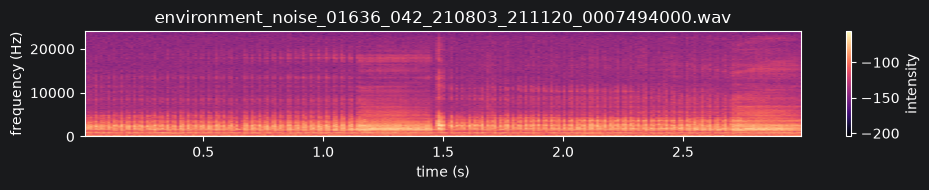

environment_noise_01857_042_210628_225556_0019977000.wav | fold=05 | true=0 | score=1.3644


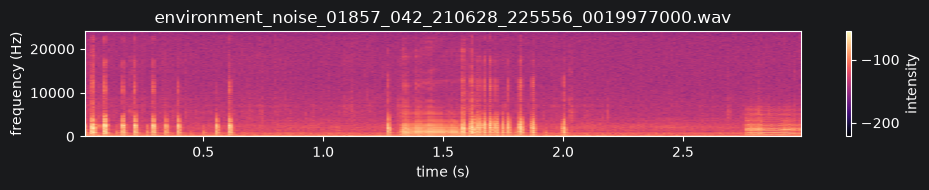

other_bird_01272_067_210716_213947_0015075000.wav | fold=04 | true=0 | score=1.3024


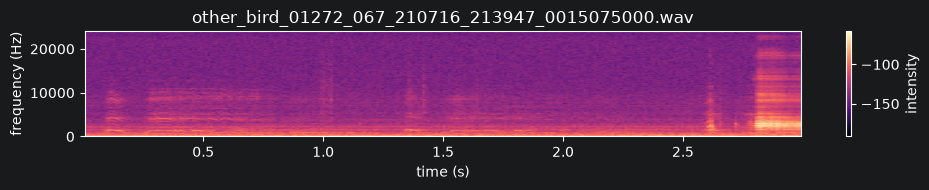

environment_noise_01966_042_210803_211120_0019731000.wav | fold=01 | true=0 | score=1.2372


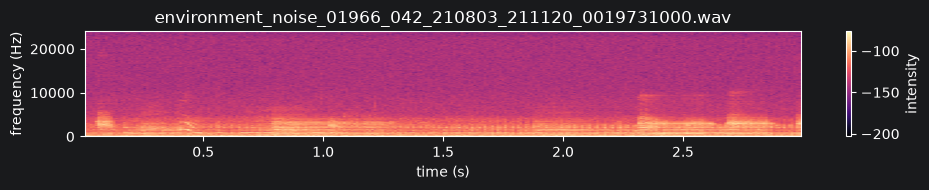

environment_noise_01894_011_210531_221151_0022530000.wav | fold=05 | true=0 | score=0.6375


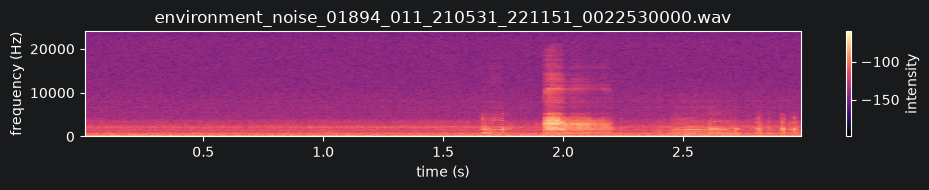

storm_petrel_00901_112_210628_225602_0012573000.wav | fold=03 | true=1 | score=-1.7549


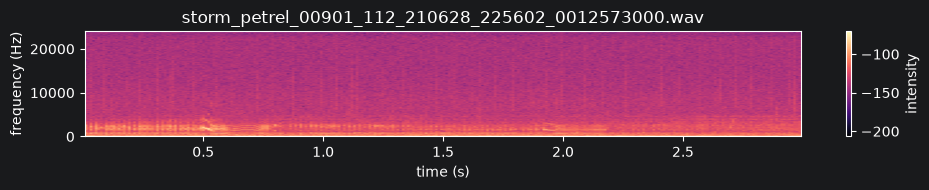

storm_petrel_00981_112_210628_225602_0013761000.wav | fold=03 | true=1 | score=-1.7327


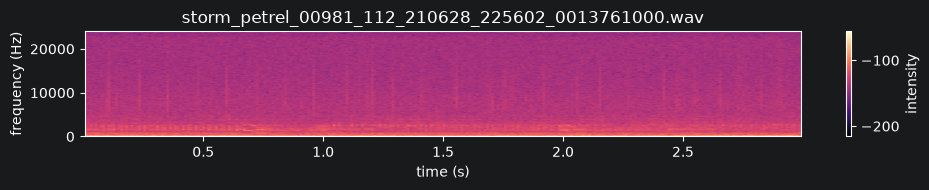

storm_petrel_00991_042_210522_184504_0031245000.wav | fold=05 | true=1 | score=-1.4367


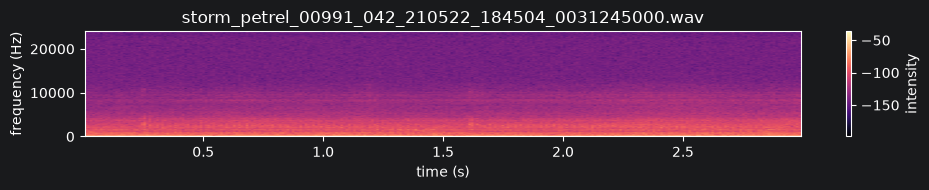

storm_petrel_00902_112_210628_225602_0012567000.wav | fold=03 | true=1 | score=0.4437


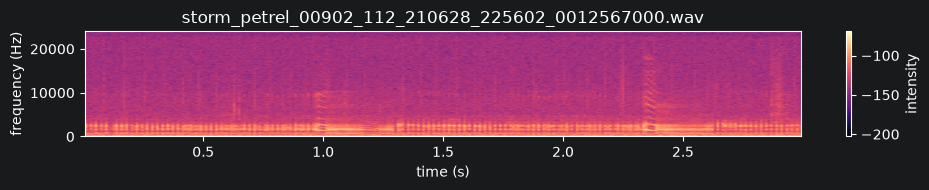

In [8]:
def resolve_clip(row):
    stored = Path(str(row['file']))
    if stored.is_file():
        return stored
    generated = CLIPS_DIR / str(row['class_folder']) / str(row['file_name'])
    if generated.is_file():
        return generated
    raise FileNotFoundError(f'Cannot find clip {row["file_name"]}')

def show_clip(row):
    path = resolve_clip(row)
    data, rate = sf.read(path)
    if getattr(data, 'ndim', 1) > 1:
        data = data.mean(axis=1)
    print(f'{path.name} | fold={row["outer_fold"]} | true={row["true_label"]} | score={row["score"]:.4f}')
    display(Audio(data, rate=rate))
    plt.figure(figsize=(10, 2))
    plt.specgram(data, Fs=rate, NFFT=1024, noverlap=512, cmap='magma')
    plt.colorbar(label='intensity')
    plt.title(path.name)
    plt.xlabel('time (s)')
    plt.ylabel('frequency (Hz)')
    plt.tight_layout()
    plt.show()

for _, row in false_positives.head(5).iterrows():
    show_clip(row)

for _, row in false_negatives.head(5).iterrows():
    show_clip(row)